# Support Vector Machine
# Karunya paliwal
# C1 - 14

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler , OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

In [ ]:
df = pd.read_csv('ai4i2020 - ai4i2020.csv')

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.isnull()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.columns


Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### 1. Barplot: Distribution of Machine Failures

/tmp/ipykernel_703/2846889921.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Machine failure', palette='Set2')


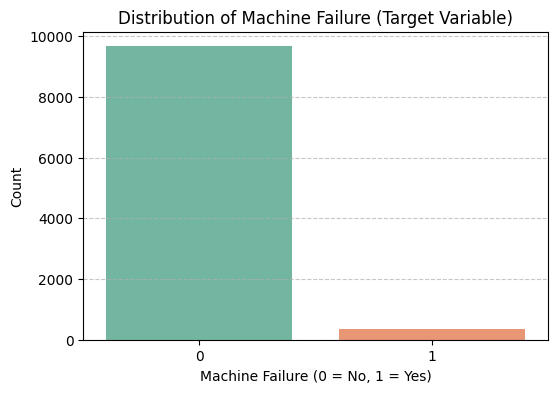

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Machine failure', palette='Set2')
plt.title('Distribution of Machine Failure (Target Variable)')
plt.xlabel('Machine Failure (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

### 2. Histogram: Distribution of Air and Process Temperatures

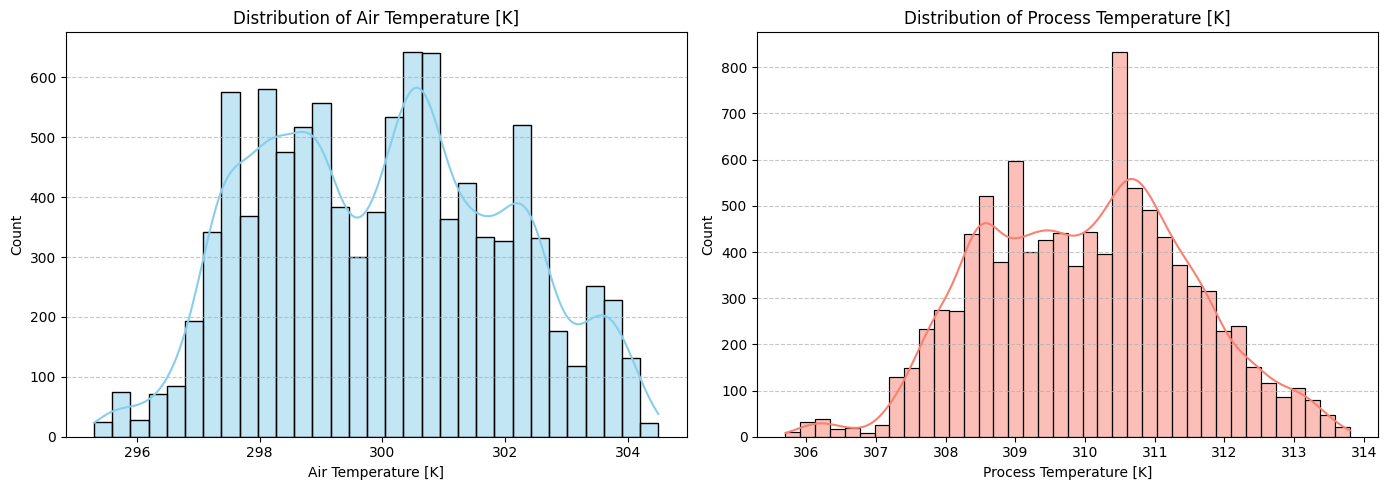

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['Air temperature [K]'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Air Temperature [K]')
axes[0].set_xlabel('Air Temperature [K]')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

sns.histplot(df['Process temperature [K]'], kde=True, ax=axes[1], color='salmon')
axes[1].set_title('Distribution of Process Temperature [K]')
axes[1].set_xlabel('Process Temperature [K]')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### 3. Heatmap: Correlation Matrix

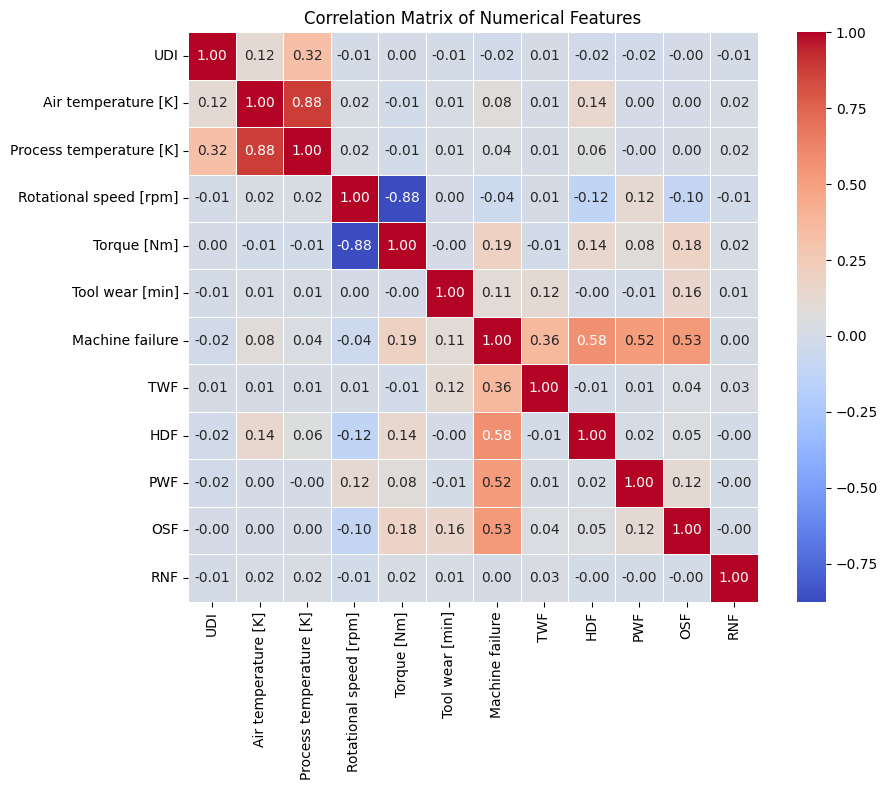

In [ ]:
plt.figure(figsize=(10, 8))
numerical_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numerical_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.tight_layout()
plt.show()

In [ ]:
X = df[
    [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]",
    ]
]

In [ ]:
y = df["Machine failure"]

In [ ]:
print('Input Shape')
print(X.shape)
print('Output Shape')
print(y.shape)

Input Shape
(10000, 6)
Output Shape
(10000,)


In [ ]:
categorical_features = ['Type']
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

In [ ]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 42)

In [ ]:
preprocessing = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features,
        ),
        (
            "cat",
            OneHotEncoder(),
            categorical_features,
        ),
    ]
)


In [ ]:
linear_svm = Pipeline(
    steps=[
        ("Preprocessing",preprocessing),
        ("classifiers",SVC(kernel = 'linear'))
    ]
)
linear_svm.fit(X_train , y_train)

Pipeline(steps=[('Preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Type'])])),
                ('classifiers', SVC(kernel='linear'))])

In [ ]:
y_pred_linear = linear_svm.predict(X_test)

In [ ]:
accurcay_linear = accuracy_score(
    y_test ,
    y_pred_linear
)
precision_linear = precision_score(
    y_test ,
    y_pred_linear
    )
recall_linear = recall_score(
    y_test ,
    y_pred_linear
)
f1_linear = f1_score(
    y_test ,
    y_pred_linear
)

print(f"Accuracy: {accurcay_linear}")
print(f"Precision: {precision_linear}")
print(f"Recall: {recall_linear}")
print(f"F1 Score: {f1_linear}")

Accuracy: 0.9695
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names=["No Failure", "Failure"]
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1939
     Failure       0.00      0.00      0.00        61

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.94      0.97      0.95      2000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


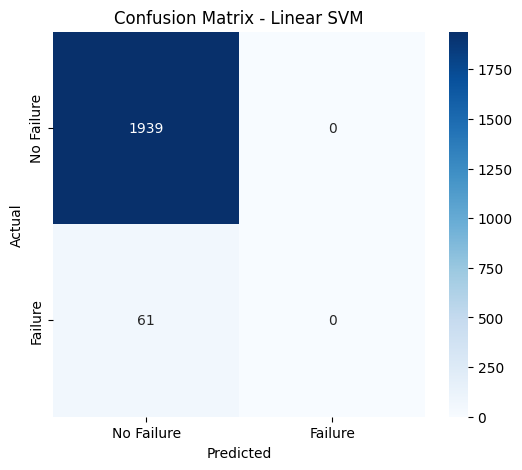

In [ ]:
cm_linear = confusion_matrix(y_test , y_pred_linear)

plt.figure(figsize=(6, 5))

sns.heatmap(cm_linear, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Failure", "Failure"],
            yticklabels=["No Failure", "Failure"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")

plt.show()

In [ ]:
rbf_svm = Pipeline(
    steps=[
        ("Preprocessing",preprocessing),
        ("classifiers",SVC(kernel = 'rbf'))
    ]
)
rbf_svm.fit(X_train , y_train)

print("RBF SVM Model Training completed.")

RBF SVM Model Training completed.


In [ ]:
y_pred_rbf = rbf_svm.predict(X_test)

In [ ]:
accuracy_rbf = accuracy_score(
    y_test,
    y_pred_rbf
)
precision_rbf = precision_score(
    y_test,
    y_pred_rbf
)

recall_rbf = recall_score(
    y_test,
    y_pred_rbf
)
f1_rbf = f1_score(
    y_test,
    y_pred_rbf
)

print(f"Accuracy: {accuracy_rbf}")
print(f"Precision: {precision_rbf}")
print(f"Recall: {recall_rbf}")
print(f"F1 Score: {f1_rbf}")

Accuracy: 0.977
Precision: 0.8571428571428571
Recall: 0.29508196721311475
F1 Score: 0.43902439024390244


In [ ]:
accuracy_rbf = accuracy_score (y_test,y_pred_rbf)
precision_rbf = precision_score (y_test,y_pred_rbf,zero_division=0)
recall_rbf = recall_score (y_test,y_pred_rbf,zero_division=0)
f1_rbf = f1_score (y_test,y_pred_rbf,zero_division=0)

print(f"Accuracy: {accuracy_rbf}")
print(f"Precision: {precision_rbf}")
print(f"Recall: {recall_rbf}")
print(f"F1 Score: {f1_rbf}")

Accuracy: 0.977
Precision: 0.8571428571428571
Recall: 0.29508196721311475
F1 Score: 0.43902439024390244


In [ ]:
print(classification_report(y_test,y_pred_rbf,target_names=["No Failure","Failure"]
                            )
)

              precision    recall  f1-score   support

  No Failure       0.98      1.00      0.99      1939
     Failure       0.86      0.30      0.44        61

    accuracy                           0.98      2000
   macro avg       0.92      0.65      0.71      2000
weighted avg       0.97      0.98      0.97      2000



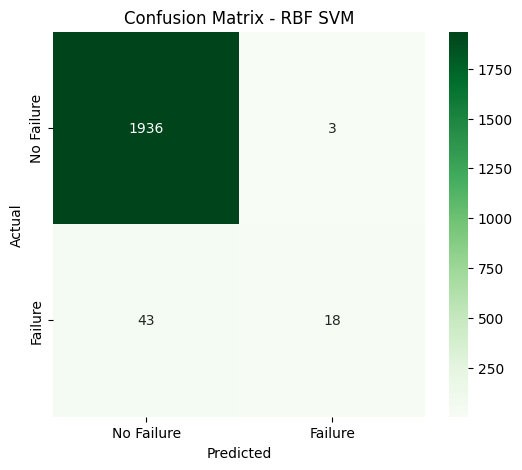

In [ ]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 5))

sns.heatmap(cm_rbf, annot=True, fmt="d", cmap="Greens",
            xticklabels=["No Failure", "Failure"],
            yticklabels=["No Failure", "Failure"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - RBF SVM")

plt.show()

In [ ]:
comparison = pd.DataFrame({
    'Model': ['Linear SVM', 'RBF SVM'],
    'Accuracy': [accurcay_linear, accuracy_rbf],
    'Precision': [precision_linear, precision_rbf],
    'Recall': [recall_linear, recall_rbf],
    'F1 Score': [f1_linear, f1_rbf]
})

comparison


,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.9695,0.000000,0.000000,0.000000
1,RBF SVM,0.9770,0.857143,0.295082,0.439024


# **Hyperparameters**

In [ ]:
pipeline = Pipeline(
    steps=[
        ('preprocessing', preprocessing),
        ('classifier', SVC())
    ]
)

In [ ]:
param_grid = [{"classifier_kernel}" : ["linear"],"classifier_C":[0.1,1,10,100]},
              {"classifier_kernel":["rbf"],"classifier_C":[0.1,1,10,100],"classifier_gamma" :
               ["scale",0.1,1,10,100]}]

In [ ]:
grid_search = GridSearchCV(pipeline,param_grid,cv=5,verbose=1,n_jobs=-1)

In [ ]:
grid_search.fit(X_train,y_train)


Fitting 5 folds for each of 24 candidates, totalling 120 fits


ValueError: Invalid parameter 'classifier_C' for estimator Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat', OneHotEncoder(),
                                                  ['Type'])])),
                ('classifier', SVC())]). Valid parameters are: ['memory', 'steps', 'transform_input', 'verbose'].